In [4]:
from language import TinyLanguageDataset
import torch 

def collate(batch):
    xs = [TinyLanguageDataset.to_tokens(x) for x, _ in batch]
    x_lens = torch.tensor([len(x) for x in xs])
    dec_in = [TinyLanguageDataset.to_tokens("-" + y) for _, y in batch]
    target = [TinyLanguageDataset.to_tokens(y + "@") for _, y in batch]
    return (
        torch.nn.utils.rnn.pad_sequence(xs, batch_first=True),                          # (Lx, B), padded with 0
        x_lens,
        torch.nn.utils.rnn.pad_sequence(dec_in, batch_first=True),                      # (Ly, B), padded with 0, masked via target
        torch.nn.utils.rnn.pad_sequence(target, padding_value=-100, batch_first=True),  # (Ly, B), ignored by the loss
    )

batch_size = 128
train_dataset = TinyLanguageDataset(1, 10, batch_size * 16)
train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, collate_fn=collate)

In [5]:
from rnn import RNN

rnn = RNN(len(TinyLanguageDataset.vocabulary), len(TinyLanguageDataset.vocabulary) * 32, len(TinyLanguageDataset.vocabulary))

a = "abc"
a_tokenized = TinyLanguageDataset.to_tokens(a)
TinyLanguageDataset.to_string(rnn.predict(a_tokenized))

'-cb'

In [6]:
from training import Trainer

trainer = Trainer(rnn)
trainer.fit(train_dataloader, gradient_clip_val=1)

Epoch 0: 1.3314750045537949
Epoch 1: 1.098211981356144
Epoch 2: 1.0192944705486298
Epoch 3: 0.9534866884350777
Epoch 4: 0.9096984453499317
Epoch 5: 0.8781244494020939
Epoch 6: 0.8362075537443161
Epoch 7: 0.8321542479097843
Epoch 8: 0.8050391040742397
Epoch 9: 0.779927633702755
Epoch 10: 0.7965771928429604
Epoch 11: 0.7873033136129379
Epoch 12: 0.7890623435378075
Epoch 13: 0.7555336393415928
Epoch 14: 0.7781115993857384
Epoch 15: 0.7608759067952633
Epoch 16: 0.7395489737391472
Epoch 17: 0.7786006778478622
Epoch 18: 0.7511153817176819
Epoch 19: 0.7441545240581036
Epoch 20: 0.7460308521986008
Epoch 21: 0.7303482741117477
Epoch 22: 0.7473064176738262
Epoch 23: 0.7233258932828903
Epoch 24: 0.7213668301701546
Epoch 25: 0.728610198944807
Epoch 26: 0.7196371108293533
Epoch 27: 0.7246742993593216
Epoch 28: 0.7648758664727211
Epoch 29: 0.7208821214735508
Epoch 30: 0.7328490614891052
Epoch 31: 0.7198427729308605
Epoch 32: 0.7225550562143326
Epoch 33: 0.7056929171085358
Epoch 34: 0.713226377964019

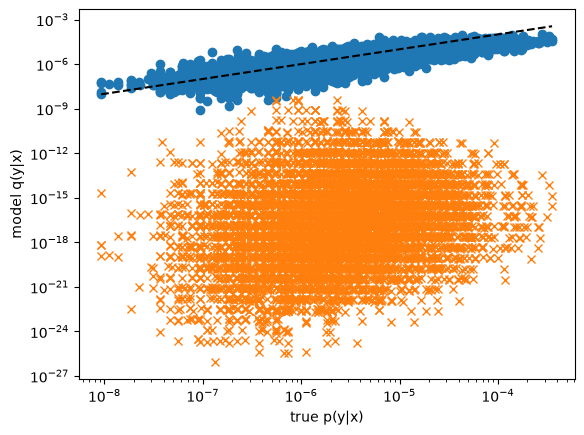

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

a = "abbaabcc"

def marginal(fn, n=100_000):
    # distribution of fn(U), U ~ Uniform(0,1), evaluated on a fine grid
    vals, counts = np.unique([fn(u) for u in (np.arange(n) + 0.5) / n], return_counts=True)
    return dict(zip(vals.tolist(), counts / n))

# for each input symbol: (P(letter index), P(repetition count)), independent
PIECES = {s: (marginal(lf), marginal(cf)) for s, (lf, cf) in TinyLanguageDataset.priors.items()}

def log_p_true(x, y):
    # dp[j] = P(the input symbols so far produced exactly y[:j])
    dp = np.zeros(len(y) + 1)
    dp[0] = 1.0
    for s in x:
        letters, counts = PIECES[s]
        new = np.zeros_like(dp)
        for j in np.nonzero(dp)[0]:
            for k, pk in counts.items():
                piece = y[j:j + k]
                if len(piece) == k and len(set(piece)) == 1:
                    new[j + k] += dp[j] * pk * letters.get(TinyLanguageDataset.vocabulary.index(piece[0]), 0.0)
        dp = new
    return np.log(dp[-1])

@torch.no_grad()
def log_q_model(model, x, y):
    logits = model(
        TinyLanguageDataset.to_tokens(x).unsqueeze(0),          # (Lx, 1)
        torch.tensor([len(x)]),
        TinyLanguageDataset.to_tokens("-" + y).unsqueeze(0),    # (Ly, 1)
    )
    return -torch.nn.functional.cross_entropy(logits.squeeze(0), TinyLanguageDataset.to_tokens(y + "@"), reduction="sum").item()

ys = list(set(TinyLanguageDataset.sample(a) for _ in range(10000)))  # observed true outputs for a
p = np.exp([log_p_true(a, y) for y in ys])
q = np.exp([log_q_model(rnn, a, y) for y in ys])

rnn_dumb = RNN(len(TinyLanguageDataset.vocabulary), len(TinyLanguageDataset.vocabulary) * 64, len(TinyLanguageDataset.vocabulary))
q_dumb = np.exp([log_q_model(rnn_dumb, a, y) for y in ys])

plt.loglog(p, q, "o")
plt.loglog(p, q_dumb, "x")
plt.plot([p.min(), p.max()], [p.min(), p.max()], "k--")  # perfect model
plt.xlabel("true p(y|x)"); plt.ylabel("model q(y|x)")
plt.show()

In [15]:
X = TinyLanguageDataset.to_tokens("-"+ a).unsqueeze(0)
X = torch.nn.functional.one_hot(X, rnn.d_in)